##Setup

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


##Load Dataset

In [11]:
import os
os.environ['KAGGLE_USERNAME'] = "tomalislam"
os.environ['KAGGLE_KEY'] = "KGAT_38919112b5b86651cbce3bb097c5357c"
import kagglehub

# Download latest version
path = kagglehub.dataset_download("tomalislam/titanic-dataset-fot-practice")

print("Path to dataset files:", path)
import shutil
shutil.copytree(path,'/content/Dataset',dirs_exist_ok=True)

Using Colab cache for faster access to the 'titanic-dataset-fot-practice' dataset.
Path to dataset files: /kaggle/input/titanic-dataset-fot-practice


'/content/Dataset'

In [15]:
df = pd.read_csv('/content/Dataset/titanic_dataset.csv')

In [16]:
numCol = ['age','fare','sibsp','parch']
catCol = ['survived', 'pclass', 'sex', 'embarked', 'class', 'who', 'adult_male', 'deck', 'embark_town', 'alone']


##Detect Outliers using Boxplot

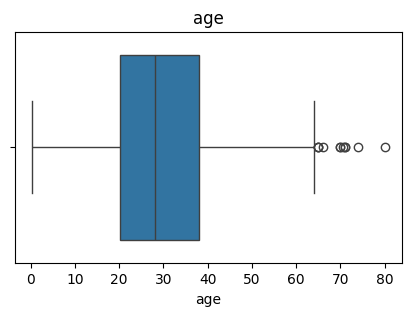

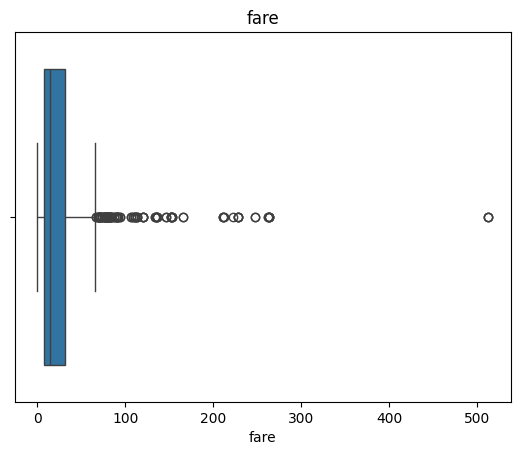

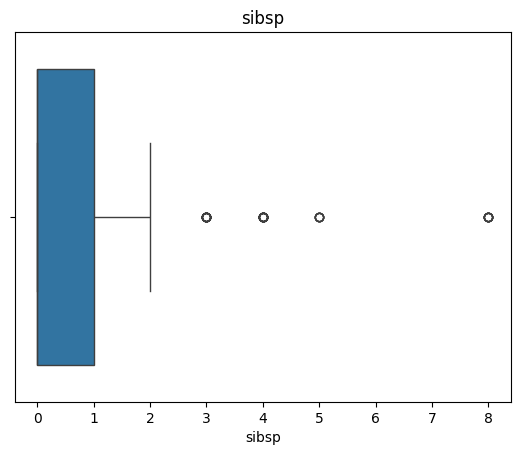

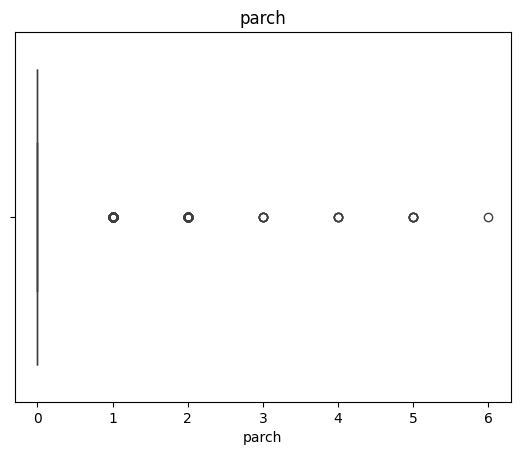

In [19]:
plt.figure(figsize=(5,3))
for col in numCol:
  sns.boxplot(x=df[col])
  plt.title(col)
  plt.show()


##IQR Method

In [28]:
def calIQR(s,factor=1.5):
  q1 = s.quantile(.25)
  q3 = s.quantile(.75)
  iqr = q3 - q1
  lowerBound = q1 - (factor*iqr)
  upperBound = q3 + (factor*iqr)
  return lowerBound,upperBound,iqr

In [35]:
dfNum = df[numCol]

for col in numCol:
  colClean = dfNum[col].dropna()
  l,u,iqr = calIQR(colClean)
  lower = (colClean < l)
  upper = (colClean > u)
  lowertotal = lower.sum()
  uppertotal = upper.sum()
  total = lowertotal + uppertotal
  print(col)
  print(f"IQR : {iqr}")
  print(f"Total Lower {lowertotal}")
  print(f"Total Upper {uppertotal}")
  print(f"Total Outlier : {total}")
  print(f"lowerbound : {l}" )
  print(f"upperbound : {u}")
  print('-'*50)

age
IQR : 17.875
Total Lower 0
Total Upper 11
Total Outlier : 11
lowerbound : -6.6875
upperbound : 64.8125
--------------------------------------------------
fare
IQR : 23.0896
Total Lower 0
Total Upper 116
Total Outlier : 116
lowerbound : -26.724
upperbound : 65.6344
--------------------------------------------------
sibsp
IQR : 1.0
Total Lower 0
Total Upper 46
Total Outlier : 46
lowerbound : -1.5
upperbound : 2.5
--------------------------------------------------
parch
IQR : 0.0
Total Lower 0
Total Upper 213
Total Outlier : 213
lowerbound : 0.0
upperbound : 0.0
--------------------------------------------------


##Z-Score Method
A Z-score tells you how many standard deviations a data point is away from the mean.
> z = (x-mean)/std -> x is datapoints

> |z| > 3  -> as outliers

* Normal distribution: Z-score works reasonably well.
* Right-skewed distribution: Legitimately high values may be flagged.
* Left-skewed distribution: Legitimately low values may be flagged.

In [36]:
  threshold = 3
  dfNum = df[numCol]
  for col in numCol:
    colClean = dfNum[col].dropna()
    m = colClean.mean()
    std = colClean.std()
    z = (colClean - m)/std
    outlier = (abs(z) > 3)
    print(f"Number of outliers in {col} : {outlier.sum()}")
    print('-'*50)

Number of outliers in age : 2
--------------------------------------------------
Number of outliers in fare : 20
--------------------------------------------------
Number of outliers in sibsp : 30
--------------------------------------------------
Number of outliers in parch : 15
--------------------------------------------------
